In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("C:/Users/Asus/Downloads/Social Media Engagement Dataset.csv")

print(df)

            post_id            timestamp day_of_week   platform  \
0      kcqbs6hxybia  2024-12-09 11:26:15      Monday  Instagram   
1      vkmervg4ioos  2024-07-28 19:59:26      Sunday    Twitter   
2      memhx4o1x6yu  2024-11-23 14:00:12    Saturday     Reddit   
3      bhyo6piijqt9  2024-09-16 04:35:25      Monday    YouTube   
4      c9dkiomowakt  2024-09-05 21:03:01    Thursday    Twitter   
...             ...                  ...         ...        ...   
11995  vpqni584supc  2025-01-10 07:55:51      Friday  Instagram   
11996  h8rvov0xym5z  2024-12-04 18:50:38   Wednesday     Reddit   
11997  14zrjm51ea3y  2024-10-24 19:11:24    Thursday   Facebook   
11998  7bdmnv3rdj8n  2024-11-12 03:07:19     Tuesday     Reddit   
11999  28cbflmapxbj  2024-05-15 20:07:23   Wednesday     Reddit   

             user_id              location language  \
0      user_52nwb0a6  Melbourne, Australia       pt   
1      user_ucryct98          Tokyo, Japan       ru   
2      user_7rrev126        Be

In [5]:
# DATA UNDERSTANDING
df.shape
df.info()
df.describe()
df.dtypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 28 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   post_id                  12000 non-null  object 
 1   timestamp                12000 non-null  object 
 2   day_of_week              12000 non-null  object 
 3   platform                 12000 non-null  object 
 4   user_id                  12000 non-null  object 
 5   location                 12000 non-null  object 
 6   language                 12000 non-null  object 
 7   text_content             12000 non-null  object 
 8   hashtags                 12000 non-null  object 
 9   mentions                 8059 non-null   object 
 10  keywords                 12000 non-null  object 
 11  topic_category           12000 non-null  object 
 12  sentiment_score          12000 non-null  float64
 13  sentiment_label          12000 non-null  object 
 14  emotion_type          

post_id                     object
timestamp                   object
day_of_week                 object
platform                    object
user_id                     object
location                    object
language                    object
text_content                object
hashtags                    object
mentions                    object
keywords                    object
topic_category              object
sentiment_score            float64
sentiment_label             object
emotion_type                object
toxicity_score             float64
likes_count                  int64
shares_count                 int64
comments_count               int64
impressions                  int64
engagement_rate            float64
brand_name                  object
product_name                object
campaign_name               object
campaign_phase              object
user_past_sentiment_avg    float64
user_engagement_growth     float64
buzz_change_rate           float64
dtype: object

In [6]:
# MISSING VALUES
df.isnull().sum()

post_id                       0
timestamp                     0
day_of_week                   0
platform                      0
user_id                       0
location                      0
language                      0
text_content                  0
hashtags                      0
mentions                   3941
keywords                      0
topic_category                0
sentiment_score               0
sentiment_label               0
emotion_type                  0
toxicity_score                0
likes_count                   0
shares_count                  0
comments_count                0
impressions                   0
engagement_rate               0
brand_name                    0
product_name                  0
campaign_name                 0
campaign_phase                0
user_past_sentiment_avg       0
user_engagement_growth        0
buzz_change_rate              0
dtype: int64

In [7]:
# Duplicate records
duplicate_count = df.duplicated().sum()
print(duplicate_count)

0


In [8]:
# Data Cleaning
df_raw = df.copy()
df_clean = df.copy()

df_clean = df_clean.drop_duplicates()

# Missing values
print(df_clean.isnull().sum())

# Data types
print(df_clean.dtypes)

post_id                       0
timestamp                     0
day_of_week                   0
platform                      0
user_id                       0
location                      0
language                      0
text_content                  0
hashtags                      0
mentions                   3941
keywords                      0
topic_category                0
sentiment_score               0
sentiment_label               0
emotion_type                  0
toxicity_score                0
likes_count                   0
shares_count                  0
comments_count                0
impressions                   0
engagement_rate               0
brand_name                    0
product_name                  0
campaign_name                 0
campaign_phase                0
user_past_sentiment_avg       0
user_engagement_growth        0
buzz_change_rate              0
dtype: int64
post_id                     object
timestamp                   object
day_of_week          

In [9]:
print(df.head())
print(df.columns)
print(df.shape)
print(df.info())

        post_id            timestamp day_of_week   platform        user_id  \
0  kcqbs6hxybia  2024-12-09 11:26:15      Monday  Instagram  user_52nwb0a6   
1  vkmervg4ioos  2024-07-28 19:59:26      Sunday    Twitter  user_ucryct98   
2  memhx4o1x6yu  2024-11-23 14:00:12    Saturday     Reddit  user_7rrev126   
3  bhyo6piijqt9  2024-09-16 04:35:25      Monday    YouTube  user_4mxuq0ax   
4  c9dkiomowakt  2024-09-05 21:03:01    Thursday    Twitter  user_l1vpox2k   

               location language  \
0  Melbourne, Australia       pt   
1          Tokyo, Japan       ru   
2        Beijing, China       ru   
3        Lagos, Nigeria       en   
4       Berlin, Germany       hi   

                                        text_content  \
0  Just tried the Chromebook from Google. Best pu...   
1  Just saw an ad for Microsoft Surface Laptop du...   
2  What's your opinion about Nike's Epic React?  ...   
3  Bummed out with my new Diet Pepsi from Pepsi! ...   
4  Just tried the Corolla from Toy

In [10]:
# CLEAN TEXT COLUMNS
text_column = df_clean.select_dtypes(include='object').columns
print(text_column)

for col in text_column:
    df_clean[col] = df_clean[col].str.strip()

Index(['post_id', 'timestamp', 'day_of_week', 'platform', 'user_id',
       'location', 'language', 'text_content', 'hashtags', 'mentions',
       'keywords', 'topic_category', 'sentiment_label', 'emotion_type',
       'brand_name', 'product_name', 'campaign_name', 'campaign_phase'],
      dtype='object')


In [11]:
# TYPECASTING TIME STAMP
df_clean['timestamp'] = pd.to_datetime(
    df_clean['timestamp'],
    errors='coerce'
)

print(df_clean.dtypes)

post_id                            object
timestamp                  datetime64[ns]
day_of_week                        object
platform                           object
user_id                            object
location                           object
language                           object
text_content                       object
hashtags                           object
mentions                           object
keywords                           object
topic_category                     object
sentiment_score                   float64
sentiment_label                    object
emotion_type                       object
toxicity_score                    float64
likes_count                         int64
shares_count                        int64
comments_count                      int64
impressions                         int64
engagement_rate                   float64
brand_name                         object
product_name                       object
campaign_name                     

In [12]:
# HANDLING MISSING VALUES
df_clean['mentions'] = df_clean['mentions'].fillna('No Mention')

print(df_clean.isnull().sum())

post_id                    0
timestamp                  0
day_of_week                0
platform                   0
user_id                    0
location                   0
language                   0
text_content               0
hashtags                   0
mentions                   0
keywords                   0
topic_category             0
sentiment_score            0
sentiment_label            0
emotion_type               0
toxicity_score             0
likes_count                0
shares_count               0
comments_count             0
impressions                0
engagement_rate            0
brand_name                 0
product_name               0
campaign_name              0
campaign_phase             0
user_past_sentiment_avg    0
user_engagement_growth     0
buzz_change_rate           0
dtype: int64


In [13]:
print(df_clean.duplicated().sum())

0


In [14]:
'''----DATA CLEANING COMPLETED-------'''

post_id                    0
timestamp                  0
day_of_week                0
platform                   0
user_id                    0
location                   0
language                   0
text_content               0
hashtags                   0
mentions                   0
keywords                   0
topic_category             0
sentiment_score            0
sentiment_label            0
emotion_type               0
toxicity_score             0
likes_count                0
shares_count               0
comments_count             0
impressions                0
engagement_rate            0
brand_name                 0
product_name               0
campaign_name              0
campaign_phase             0
user_past_sentiment_avg    0
user_engagement_growth     0
buzz_change_rate           0
dtype: int64

In [15]:
'''||||---DATA ANALYSIS---||||'''


'||||---DATA ANALYSIS---||||'

In [16]:
# Question 1: Calculate Total Likes
total_likes = df_clean['likes_count'].sum()
print("Total Likes:", total_likes)

Total Likes: 29888643


In [17]:
# Question 2:Calculate Average Likes
average_likes = df_clean['likes_count'].mean()
print("Average Likes:", average_likes)

Average Likes: 2490.72025


In [18]:
# Question 3:Calculate Total Comments
total_comments = df_clean['comments_count'].sum()
print("Total Comments:", total_comments)

Total Comments: 6052149


In [19]:
# Question 4:Calculate Average Comments
average_comments = df_clean['comments_count'].mean()
print("Average Comments:", average_comments)

Average Comments: 504.34575


In [20]:
# Question 5:Calculate Total Shares
total_shares = df_clean['shares_count'].sum()
print("Total Shares:", total_shares)

Total Shares: 12086006


In [24]:
# Question 6 : Top 10 Most engaged post
df_clean['total_engagement'] = (
    df_clean['likes_count'] +
    df_clean['comments_count'] +
    df_clean['shares_count']
)

print(df_clean[['post_id', 'total_engagement']].head())

        post_id  total_engagement
0  kcqbs6hxybia              3669
1  vkmervg4ioos              2684
2  memhx4o1x6yu              4037
3  bhyo6piijqt9              2832
4  c9dkiomowakt              4151


In [25]:
# Question 7 : Calculate Total Engagement
df_clean['total_engagement'] = (
    df_clean['likes_count'] +
    df_clean['comments_count'] +
    df_clean['shares_count']
)

print(df_clean[['post_id', 'total_engagement']].head())

        post_id  total_engagement
0  kcqbs6hxybia              3669
1  vkmervg4ioos              2684
2  memhx4o1x6yu              4037
3  bhyo6piijqt9              2832
4  c9dkiomowakt              4151


In [23]:
# Question 8: Rank Posts Based on Engagement
df_clean['engagement_rank'] = (
    df_clean['total_engagement'].rank(
        ascending=False,
        method='dense'
    )
)

print(df_clean[['post_id', 'total_engagement',
                'engagement_rank']].head(10))

        post_id  total_engagement  engagement_rank
0  kcqbs6hxybia              3669           2966.0
1  vkmervg4ioos              2684           3857.0
2  memhx4o1x6yu              4037           2638.0
3  bhyo6piijqt9              2832           3721.0
4  c9dkiomowakt              4151           2537.0
5  e8rzr949rzkr              5020           1751.0
6  32qywmjy84gk              3961           2711.0
7  wu063ci6mizp              2550           3979.0
8  9q2i3owe4tv9              2793           3758.0
9  gkyad7r8w6g5              4162           2529.0


In [26]:
# RANKING POSTS
top_ranked_posts = (
    df_clean.sort_values(
        by='engagement_rank',
        ascending=True
    ).head(10)
)

print(top_ranked_posts[['post_id',
                        'total_engagement',
                        'engagement_rank']])

            post_id  total_engagement  engagement_rank
459    7v5a8zyj4gw5              7900              1.0
11947  ycjj5zzt7mvx              7893              2.0
8925   3dh1ecglz4bd              7817              3.0
3075   wo7py9aljg3t              7793              4.0
1770   gmoeib832zbs              7764              5.0
6899   5kvuyvf38nqx              7755              6.0
11154  pvfl3d8hj7jd              7738              7.0
4093   tdgjjylpua20              7723              8.0
3881   tne7s3o4l4wd              7712              9.0
6398   kwt9yuwjsw74              7685             10.0


In [27]:
# Question 9: Platform-wise Engagement Analysis
platform_performance = (
    df_clean.groupby('platform')
    .agg({
        'likes_count': 'sum',
        'comments_count': 'sum',
        'shares_count': 'sum',
        'total_engagement': 'sum'
    })
    .sort_values(
        by='total_engagement',
        ascending=False
    )
)

print(platform_performance)

           likes_count  comments_count  shares_count  total_engagement
platform                                                              
YouTube        6045720         1235523       2479543           9760786
Facebook       6133107         1210935       2388476           9732518
Instagram      5901643         1172787       2454870           9529300
Reddit         5925053         1216551       2364548           9506152
Twitter        5883120         1216353       2398569           9498042


In [28]:
# Question 10 – Monthly Posting Trends
df_clean['month'] = df_clean['timestamp'].dt.month_name()

monthly_posts = (
    df_clean.groupby('month')['post_id']
    .count()
    .sort_values(ascending=False)
)

print(monthly_posts)

month
May          1038
December     1035
October      1029
November     1025
August       1015
March        1013
January      1007
July          996
June          979
April         975
September     974
February      914
Name: post_id, dtype: int64


In [31]:

monthly_posts = (
    df_clean.groupby(df_clean['timestamp'].dt.month)
    ['post_id'].count()
)

print(monthly_posts)

timestamp
1     1007
2      914
3     1013
4      975
5     1038
6      979
7      996
8     1015
9      974
10    1029
11    1025
12    1035
Name: post_id, dtype: int64


In [32]:
# Question 11 – Platform-wise Average Engagement
platform_avg = (
    df_clean.groupby('platform')
    .agg({
        'likes_count': 'mean',
        'comments_count': 'mean',
        'shares_count': 'mean',
        'total_engagement': 'mean'
    })
    .sort_values(
        by='total_engagement',
        ascending=False
    )
)

print(platform_avg)

           likes_count  comments_count  shares_count  total_engagement
platform                                                              
Instagram  2506.005520      497.998726   1042.407643       4046.411890
Reddit     2497.914418      512.879848    996.858347       4007.652614
YouTube    2481.822660      507.193350   1017.874795       4006.890805
Facebook   2522.874126      498.122172    982.507610       4003.503908
Twitter    2445.187032      505.549875    996.911471       3947.648379


In [33]:
# Question 12: Find Posts with Highest Impressions

highest_impressions = (
    df_clean.sort_values(
        by='impressions',
        ascending=False
    ).head(10)
)

print(highest_impressions[
    ['post_id', 'platform', 'impressions',
     'likes_count', 'total_engagement']
])

            post_id   platform  impressions  likes_count  total_engagement
8182   eh0nc8mgoer4   Facebook        99997          287               781
8936   7h2uba61bhiq   Facebook        99970         3902              4331
9262   vwb0u9ta39wm    YouTube        99970         2101              2810
7080   e0cxigmtz1aj    YouTube        99964         3300              3867
9659   tych2ncsrc0v     Reddit        99964          576              2445
6217   jpgqf6h1xiny   Facebook        99959         3757              4709
11611  x8m54xeznypo    YouTube        99957         2944              3981
7422   tvhpeuf8wj4q  Instagram        99955         2980              5179
3451   8qx0tmt573up    Twitter        99945         2868              4181
1238   cb07umibgndy     Reddit        99922          853              1831


In [34]:
# Question 13 – Calculate Engagement Rate
# Question 13: Platform-wise Engagement Rate

engagement_by_platform = (
    df_clean.groupby('platform')
    .agg({
        'engagement_rate': 'mean'
    })
    .sort_values(
        by='engagement_rate',
        ascending=False
    )
)

print(engagement_by_platform)

           engagement_rate
platform                  
Instagram         0.287131
Facebook          0.286412
YouTube           0.279185
Reddit            0.278727
Twitter           0.259331


In [35]:
# Question 14 – Top 10 Most Used Hashtags
# Question 14 – Top 10 Hashtags

hashtag_analysis = (
    df_clean['hashtags']
    .str.split(',')
    .explode()
    .str.strip()
)

top_hashtags = hashtag_analysis.value_counts().head(10)

print(top_hashtags)

#Fitness         885
#Reviews         884
#BestValue       870
#SpecialOffer    849
#Promo           847
#Fashion         846
#Trending        845
#Health          845
#Premium         845
#Sustainable     844
Name: hashtags, dtype: int64


In [38]:
# Question 15 – Sentiment Analysis
# Question 15 – Sentiment Analysis

sentiment_count = df_clean['sentiment_label'].value_counts()

print(sentiment_count)

Negative    4854
Positive    4839
Neutral     2307
Name: sentiment_label, dtype: int64


In [39]:
# Question 16 – Platform-wise Sentiment Analysis
# Question 16 – Platform-wise Sentiment

platform_sentiment = pd.crosstab(
    df_clean['platform'],
    df_clean['sentiment_label']
)

print(platform_sentiment)

sentiment_label  Negative  Neutral  Positive
platform                                    
Facebook              985      469       977
Instagram             938      452       965
Reddit                991      462       919
Twitter               933      470      1003
YouTube              1007      454       975


In [40]:
# Question 17 – Day-wise Post Analysis
# Question 17 – Day-wise Post Analysis

day_posts = (
    df_clean['day_of_week']
    .value_counts()
)

print(day_posts)

Wednesday    1771
Friday       1723
Monday       1720
Thursday     1718
Sunday       1716
Tuesday      1677
Saturday     1675
Name: day_of_week, dtype: int64


In [41]:
# Question 18 – Day-wise Average Engagement
# Question 18 – Day-wise Average Engagement

day_engagement = (
    df_clean.groupby('day_of_week')['total_engagement']
    .mean()
    .sort_values(ascending=False)
)

print(day_engagement)

day_of_week
Sunday       4017.267483
Saturday     4015.574328
Wednesday    4015.490683
Tuesday      4014.406082
Thursday     3998.520373
Monday       3994.572674
Friday       3960.164829
Name: total_engagement, dtype: float64


In [42]:
# Question 19 – Campaign-wise Engagement Analysis
# Question 19 – Campaign-wise Engagement

campaign_engagement = (
    df_clean.groupby('campaign_name')['total_engagement']
    .sum()
    .sort_values(ascending=False)
)

print(campaign_engagement)

campaign_name
CyberMonday              2291420
LocalTouchpoints         2286975
InnovationX              2229252
LoyaltyRewards           2211268
BackToSchool             2203893
LaunchWave               2174372
WinterWonders            2150755
SummerDreams             2113798
ValentinesDeals          2111504
EarthDay                 2073823
HolidaySpecial           2073568
SummerSale               2071184
CustomerFirst            2068347
SpringBlast2025          2030181
PowerRelease             2020734
ReferralBonus            2007054
NextGeneration           2004212
GlobalCampaign           2001792
FallCollection           2001690
NewYearNewYou            1997489
BlackFriday              1983646
SustainableFuture        1967273
DigitalTransformation    1952568
Name: total_engagement, dtype: int64


In [43]:
# Question 20 – Campaign-wise Average Engagement
# Question 20 – Campaign-wise Average Engagement

campaign_avg = (
    df_clean.groupby('campaign_name')['total_engagement']
    .mean()
    .sort_values(ascending=False)
)

print(campaign_avg)

campaign_name
SummerDreams             4136.590998
CustomerFirst            4071.549213
ValentinesDeals          4060.584615
EarthDay                 4058.362035
NextGeneration           4057.109312
LoyaltyRewards           4049.941392
DigitalTransformation    4034.231405
LocalTouchpoints         4033.465608
BackToSchool             4021.702555
WinterWonders            4020.102804
FallCollection           4003.380000
HolidaySpecial           4003.027027
CyberMonday              3998.987784
LaunchWave               3982.366300
InnovationX              3980.807143
SpringBlast2025          3980.747059
NewYearNewYou            3971.151093
BlackFriday              3959.373253
PowerRelease             3954.469667
SustainableFuture        3942.430862
ReferralBonus            3920.027344
SummerSale               3915.281664
GlobalCampaign           3894.536965
Name: total_engagement, dtype: float64


In [44]:
# Question 21 – Topic-wise Engagement Analysis
# Question 21 – Topic-wise Engagement


topic_engagement = (
    df_clean.groupby('topic_category')['total_engagement']
    .mean()
    .sort_values(ascending=False)
)

print(topic_engagement)

topic_category
Returns      4058.903566
Product      4029.693856
Support      4000.614792
Pricing      3993.111926
Marketing    3968.638277
Delivery     3965.113949
Name: total_engagement, dtype: float64


In [45]:
# Question 22 – Sentiment-wise Average Engagement
# Question 22 – Sentiment-wise Average Engagement

sentiment_engagement = (
    df_clean.groupby('sentiment_label')['total_engagement']
    .mean()
    .sort_values(ascending=False)
)

print(sentiment_engagement)

sentiment_label
Negative    4024.274825
Positive    3994.415788
Neutral     3972.254010
Name: total_engagement, dtype: float64


In [46]:
# Question 23 – Emotion-wise Engagement Analysis
# Question 23 – Emotion-wise Engagement

emotion_engagement = (
    df_clean.groupby('emotion_type')['total_engagement']
    .mean()
    .sort_values(ascending=False)
)

print(emotion_engagement)

emotion_type
Sad         4050.473642
Angry       4009.790678
Excited     3996.480706
Happy       3990.649362
Confused    3961.669035
Name: total_engagement, dtype: float64


In [47]:
# Question 24 – Brand-wise Engagement Analysis
# Question 24 – Brand-wise Engagement

brand_engagement = (
    df_clean.groupby('brand_name')['total_engagement']
    .mean()
    .sort_values(ascending=False)
)

print(brand_engagement)

brand_name
Amazon       4120.415573
Samsung      4063.000822
Apple        4035.354866
Adidas       4010.494711
Coca-Cola    3999.563512
Pepsi        3995.425354
Toyota       3978.770869
Nike         3951.627564
Google       3948.092105
Microsoft    3927.779661
Name: total_engagement, dtype: float64


In [48]:
# Question 25 – Product-wise Engagement Analysis
# Question 25 – Product-wise Engagement

product_engagement = (
    df_clean.groupby('product_name')['total_engagement']
    .mean()
    .sort_values(ascending=False)
)

print(product_engagement)

product_name
Kindle                   4256.462857
Galaxy Tab               4233.394089
AirPods Pro              4231.964789
Apple Watch              4187.142857
Tundra                   4183.635135
                            ...     
RAV4                     3774.049296
Surface Laptop           3773.777228
Epic React               3727.313725
Xbox Elite Controller    3674.024631
Samba                    3673.216783
Name: total_engagement, Length: 70, dtype: float64


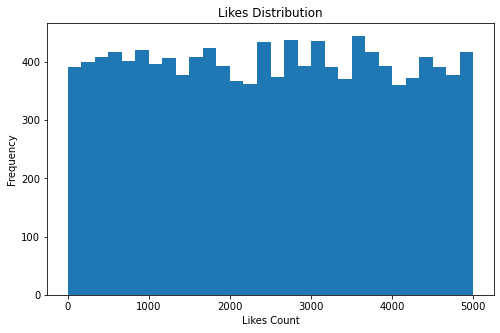

In [49]:
# Chart 1 – Likes Distribution

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(df_clean['likes_count'], bins=30)

plt.title('Likes Distribution')
plt.xlabel('Likes Count')
plt.ylabel('Frequency')

plt.show()

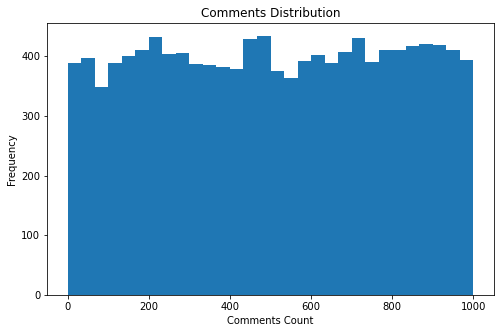

In [50]:
# Chart 2 – Comments Distribution

plt.figure(figsize=(8, 5))

plt.hist(df_clean['comments_count'], bins=30)

plt.title('Comments Distribution')
plt.xlabel('Comments Count')
plt.ylabel('Frequency')

plt.show()

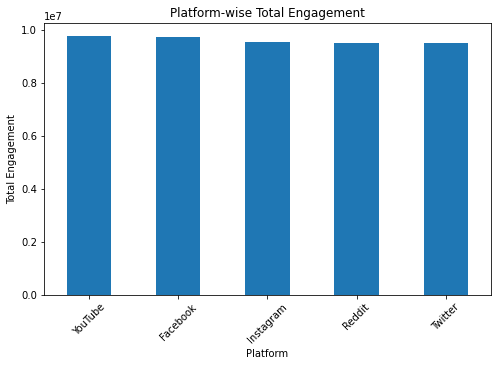

In [51]:
# Chart 3 – Platform-wise Total Engagement

platform_performance['total_engagement'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Platform-wise Total Engagement')
plt.xlabel('Platform')
plt.ylabel('Total Engagement')
plt.xticks(rotation=45)

plt.show()

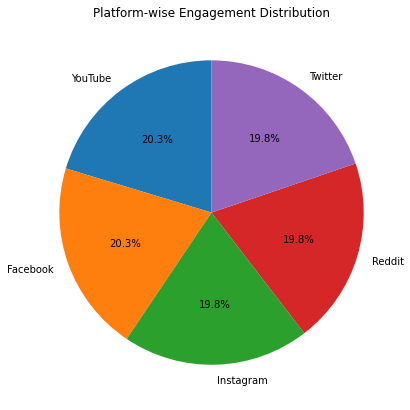

In [52]:
# Chart 4 – Platform-wise Engagement Pie Chart

plt.figure(figsize=(7, 7))

plt.pie(
    platform_performance['total_engagement'],
    labels=platform_performance.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Platform-wise Engagement Distribution')

plt.show()

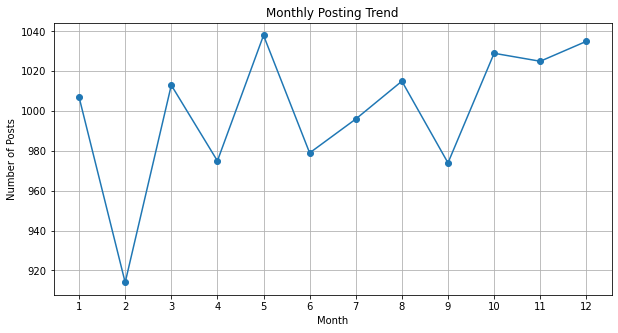

In [53]:
# Chart 5 – Monthly Posting Trend

monthly_trend = (
    df_clean.groupby(df_clean['timestamp'].dt.month)['post_id']
    .count()
)

plt.figure(figsize=(10, 5))

plt.plot(monthly_trend.index, monthly_trend.values, marker='o')

plt.title('Monthly Posting Trend')
plt.xlabel('Month')
plt.ylabel('Number of Posts')
plt.xticks(range(1, 13))

plt.grid(True)

plt.show()

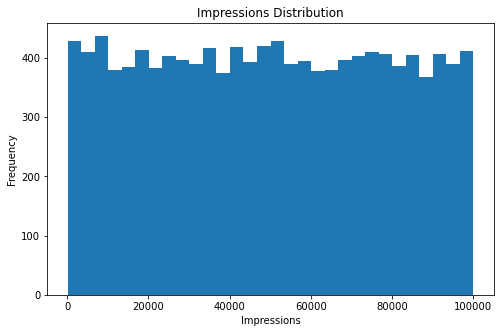

In [54]:
# Chart 6 – Impressions Distribution

plt.figure(figsize=(8, 5))

plt.hist(df_clean['impressions'], bins=30)

plt.title('Impressions Distribution')
plt.xlabel('Impressions')
plt.ylabel('Frequency')

plt.show()

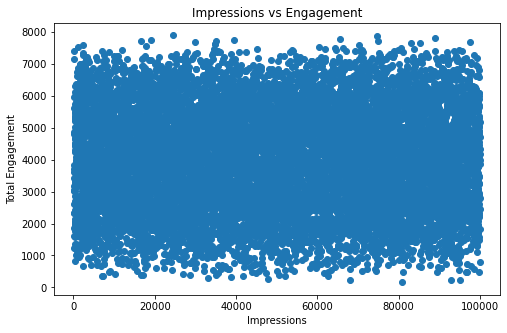

In [55]:
# Chart 7 – Reach vs Engagement (Scatter Plot)
# Chart 7 – Impressions vs Engagement

plt.figure(figsize=(8, 5))

plt.scatter(
    df_clean['impressions'],
    df_clean['total_engagement']
)

plt.title('Impressions vs Engagement')
plt.xlabel('Impressions')
plt.ylabel('Total Engagement')

plt.show()

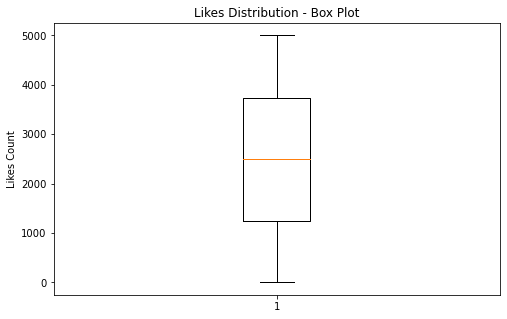

In [56]:
# Chart 8 – Likes Distribution (Box Plot)
# Chart 8 – Likes Box Plot

plt.figure(figsize=(8, 5))

plt.boxplot(df_clean['likes_count'])

plt.title('Likes Distribution - Box Plot')
plt.ylabel('Likes Count')

plt.show()

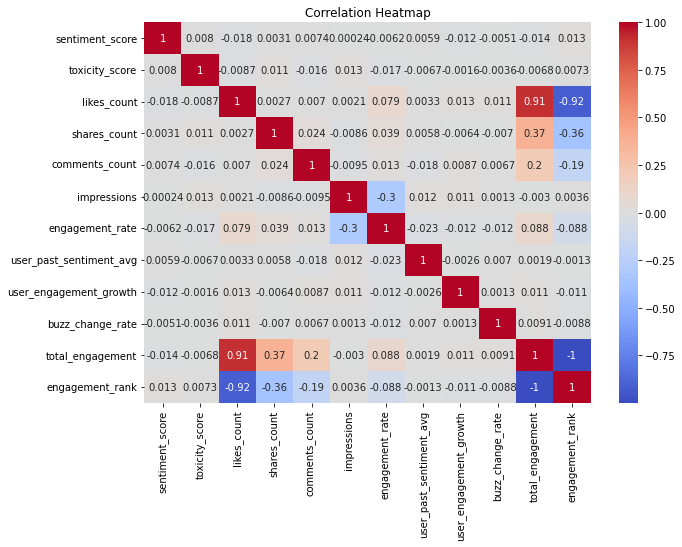

In [57]:
# Chart 9 – Correlation Heatmap

import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    df_clean.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')

plt.show()

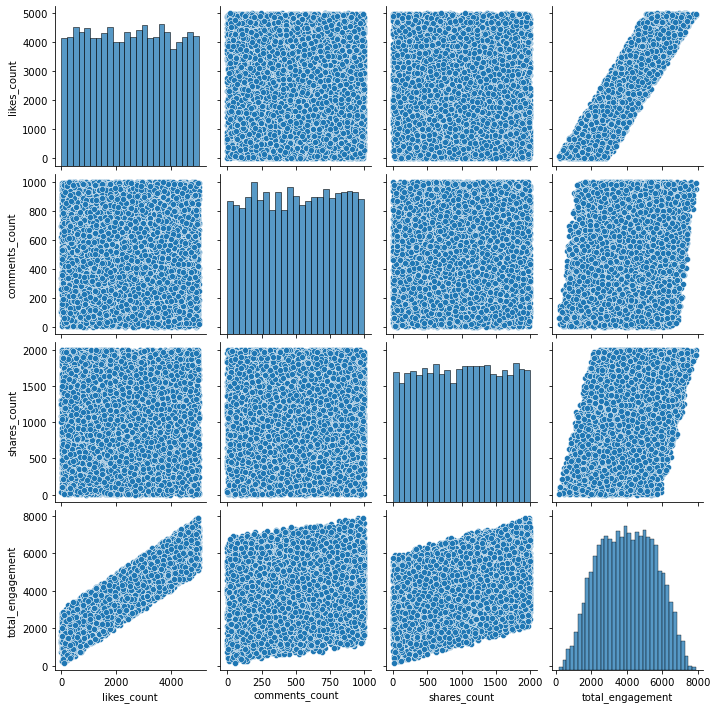

In [58]:
# Chart 10 – Pair Plot

sns.pairplot(
    df_clean[
        ['likes_count', 'comments_count',
         'shares_count', 'total_engagement']
    ]
)

plt.show()

In [59]:
 '''Save Cleaned Dataset'''

df_clean.to_csv('social_media_cleaned.csv', index=False)

print("Cleaned Dataset Saved Successfully!")

Cleaned Dataset Saved Successfully!


In [60]:
# Statistical Summary

statistical_summary = df_clean.describe()

print(statistical_summary)

       sentiment_score  toxicity_score  likes_count  shares_count  \
count     12000.000000    12000.000000  12000.00000  12000.000000   
mean          0.000553        0.503868   2490.72025   1007.167167   
std           0.583563        0.288198   1441.53253    575.072282   
min          -0.999800        0.000000      0.00000      0.000000   
25%          -0.503200        0.251400   1236.00000    510.000000   
50%          -0.006200        0.505950   2496.00000   1018.000000   
75%           0.513525        0.756200   3723.25000   1501.000000   
max           0.999900        0.999900   5000.00000   2000.000000   

       comments_count   impressions  engagement_rate  user_past_sentiment_avg  \
count     12000.00000  12000.000000     12000.000000             12000.000000   
mean        504.34575  49811.338500         0.278137                 0.001472   
std         288.68416  28930.289451         1.149206                 0.576627   
min           0.00000    130.000000         0.001880  

In [61]:
# Task 3 – Business Insights

print("SOCIAL MEDIA BUSINESS INSIGHTS")

print("1. Highest Engagement Platform: YouTube")
print("2. Highest Average Engagement Platform: Instagram")
print("3. Highest Engagement Campaign: CyberMonday")
print("4. Highest Average Campaign Engagement: SummerDreams")
print("5. Highest Engagement Topic: Returns")
print("6. Highest Engagement Brand: Amazon")
print("7. Highest Engagement Product: Kindle")
print("8. Highest Engagement Day: Sunday")
print("9. Most Used Hashtag: #Fitness")
print("10. Highest Negative Sentiment: Negative")

SOCIAL MEDIA BUSINESS INSIGHTS
1. Highest Engagement Platform: YouTube
2. Highest Average Engagement Platform: Instagram
3. Highest Engagement Campaign: CyberMonday
4. Highest Average Campaign Engagement: SummerDreams
5. Highest Engagement Topic: Returns
6. Highest Engagement Brand: Amazon
7. Highest Engagement Product: Kindle
8. Highest Engagement Day: Sunday
9. Most Used Hashtag: #Fitness
10. Highest Negative Sentiment: Negative


In [62]:
# Task 4 – PDF Report

from matplotlib.backends.backend_pdf import PdfPages
from matplotlib import pyplot as plt


In [63]:
with PdfPages('Social_Media_Analysis_Report.pdf') as pdf:

    # Page 1 – Statistical Summary
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.axis('off')

    ax.set_title(
        'Social Media Analysis - Statistical Summary',
        fontsize=16
    )

    summary = df_clean.describe().round(2)

    ax.table(
        cellText=summary.values,
        rowLabels=summary.index,
        colLabels=summary.columns,
        loc='center'
    )

    pdf.savefig(fig, bbox_inches='tight')
    plt.close(fig)

print("PDF Report Created Successfully!")

PDF Report Created Successfully!


In [64]:
# Save Business Insights in CSV
# Task 5 – Export Business Insights

business_insights = {
    'Insights': [
        'Highest Engagement Platform: YouTube',
        'Highest Average Engagement Platform: Instagram',
        'Highest Engagement Campaign: CyberMonday',
        'Highest Average Campaign Engagement: SummerDreams',
        'Highest Engagement Topic: Returns',
        'Highest Engagement Brand: Amazon',
        'Highest Engagement Product: Kindle',
        'Highest Engagement Day: Sunday',
        'Most Used Hashtag: #Fitness',
        'Highest Negative Sentiment: Negative'
    ]
}

insights_df = pd.DataFrame(business_insights)

insights_df.to_csv('business_insights.csv', index=False)

print("Business Insights Saved Successfully!")

Business Insights Saved Successfully!


In [1]:
import os

print(os.getcwd())

C:\Users\Asus\Theta b
